# Point and ask: a voice and vision assistant with NVIDIA Nemotron

Author: [Zain Hasan](https://x.com/ZainHasan6)

<a target="_blank" href="https://colab.research.google.com/github/togethercomputer/together-cookbook/blob/main/apps/Voice_Vision_Assistant.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Introduction

Point your phone at something, ask a question out loud, and hear the answer. Building that takes three models:

| Stage | Model on Together AI | What it does |
| :-- | :-- | :-- |
| Speech to text | [NVIDIA Nemotron 3.5 ASR Streaming 0.6B](https://docs.together.ai/docs/inference/transcription/overview) (`nvidia/nemotron-3.5-asr-streaming-0.6b`) | Transcribes the question over a streaming WebSocket |
| Vision and reasoning | [NVIDIA Nemotron 3.5 Super VL](https://api.together.ai/models/nvidia/NVIDIA-Nemotron-3.5-Super-VL) (`nvidia/NVIDIA-Nemotron-3.5-Super-VL`) | Looks at the photo, answers the question, calls tools |
| Text to speech | [Cartesia Sonic 3](https://docs.together.ai/docs/inference/text-to-speech/overview) (`cartesia/sonic-3`) | Reads the answer aloud |

We build the assistant end to end and give it two tools: a calculator, so it never does arithmetic in its head, and a shopping list it can add to. Then we run it on four photos (a grocery receipt, a nutrition label, a home-cooked meal, and a dinner table) and measure how long each stage takes and what one question costs.

Instead of a microphone, we synthesize each spoken question with a second TTS voice, so anyone running the notebook asks the same questions. The last section shows how to use your own recording.

## Setup

The `realtime` extra installs the WebSocket client that streaming speech-to-text needs.

In [1]:
%pip install -qU "together[realtime]>=3.0.0" "pillow>=11.3.0" "numpy>=1.22.0" "requests>=2.33.0" "pandas>=2.0.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import ast
import asyncio
import base64
import io
import json
import operator
import os
import tempfile
import time
import wave

import numpy as np
import pandas as pd
import requests
from IPython.display import Audio, Markdown, display
from PIL import Image
from together import AsyncTogether, Together

# Both clients read TOGETHER_API_KEY from the environment
client = Together()
async_client = AsyncTogether()

ASR_MODEL = "nvidia/nemotron-3.5-asr-streaming-0.6b"
VLM_MODEL = "nvidia/NVIDIA-Nemotron-3.5-Super-VL"
TTS_MODEL = "cartesia/sonic-3"

ASSISTANT_VOICE = "helpful woman"
USER_VOICE = "midwestern man"  # stands in for a microphone in this notebook
SAMPLE_RATE = 16_000  # the ASR model takes 16 kHz mono 16-bit PCM

# Pricing from https://docs.together.ai/docs/serverless/models
ASR_PRICE_PER_MIN = 0.0015
VLM_PRICE_IN, VLM_PRICE_OUT = 0.15, 0.50  # $ per 1M tokens
TTS_PRICE_PER_CHAR = 65.00 / 1e6

## The photos

We use four images that already live in this repository, so they load the same way locally and in Colab.

In [3]:
ASSETS = "https://raw.githubusercontent.com/togethercomputer/together-cookbook/main/inference/vision/assets"
PHOTOS = {
    "receipt": f"{ASSETS}/1_wJI9IoO7g5QB5t8oPftBMw.jpg",
    "snack": f"{ASSETS}/protein-candy.webp",
    "dinner": f"{ASSETS}/omni_recognition/sample-food.jpeg",
    "party": f"{ASSETS}/spatial_understanding/dining_table.png",
}


def load_photo(url: str, max_side: int = 1280) -> Image.Image:
    image = Image.open(io.BytesIO(requests.get(url, timeout=60).content)).convert("RGB")
    image.thumbnail((max_side, max_side))
    return image


def to_data_url(image: Image.Image) -> str:
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=90)
    return "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode()


photos = {name: load_photo(url) for name, url in PHOTOS.items()}
for name, image in photos.items():
    print(name, image.size)

receipt (400, 533)
snack (800, 800)
dinner (960, 1280)
party (1280, 959)


## Speech to text

Nemotron 3.5 ASR is a streaming model: it's served over a WebSocket rather than the file-upload transcription endpoint. The SDK's `client.beta.realtime.transcription()` session handles the connection.

We send 16 kHz PCM audio in 100 ms chunks at real-time pace, the way a microphone delivers it. The server transcribes as audio arrives, and `flush()` finalizes whatever it has received so far. If you push a whole recording faster than real time, the flush can arrive before the server has processed the last words, and the end of the question gets cut off. We also append half a second of very quiet noise after the speech so the last word is finalized. (Pure digital silence trips the SDK's "is the microphone live?" warning.)

Because the audio streams while the user is talking, we measure how long the transcript takes after the user stops speaking.

First, a helper that produces a spoken question. It asks Cartesia for raw 16-bit PCM at 16 kHz, exactly the format the ASR model expects.

In [4]:
def synthesize_speech(text: str, voice: str = USER_VOICE) -> bytes:
    """Text to 16 kHz mono 16-bit PCM."""
    response = client.audio.speech.create(
        model=TTS_MODEL,
        input=text,
        voice=voice,
        response_format="raw",
        response_encoding="pcm_s16le",
        sample_rate=SAMPLE_RATE,
    )
    return response.read()


def pcm_to_wav(pcm: bytes, sample_rate: int = SAMPLE_RATE) -> bytes:
    buffer = io.BytesIO()
    with wave.open(buffer, "wb") as wav:
        wav.setnchannels(1)
        wav.setsampwidth(2)
        wav.setframerate(sample_rate)
        wav.writeframes(pcm)
    return buffer.getvalue()


CHUNK_BYTES = SAMPLE_RATE * 2 // 10  # 100 ms of 16-bit audio
# Half a second of very quiet noise to follow the speech
ROOM_TONE = np.random.default_rng(0).normal(0, 2, SAMPLE_RATE // 2).astype(np.int16).tobytes()


async def transcribe(pcm: bytes) -> tuple[str, float]:
    """Stream PCM at real-time pace, like a microphone. Returns (transcript, seconds from end of speech to transcript)."""
    async with async_client.beta.realtime.transcription(model=ASR_MODEL, sample_rate=SAMPLE_RATE) as session:
        for start in range(0, len(pcm), CHUNK_BYTES):
            await session.append(pcm[start : start + CHUNK_BYTES])
            await asyncio.sleep(0.1)
        speech_ended = time.time()
        await session.append(ROOM_TONE)
        transcript = await session.flush(quiescence=1.0)
    return " ".join(transcript.split()), time.time() - speech_ended


question_audio = synthesize_speech("Hey, can you hear me? What's the weather like on Mars?")
display(Audio(pcm_to_wav(question_audio)))
transcript, latency = await transcribe(question_audio)
print(f"Transcript: {transcript}\n{latency:.1f}s after the speech ended")

Transcript: Hey, can you hear me? What's the weather like on Mars
3.3s after the speech ended


## The vision model and its tools

The assistant's answers will be spoken, so the system prompt asks for short, plain sentences with no markdown, and amounts said the way a person would say them.

Nemotron 3.5 Super VL reasons before answering by default, and we leave it on. Turning reasoning off would save latency, but in our testing it made the assistant unreliable: it often skipped the tools, said it had added items to the shopping list without calling the tool, picked the wrong most expensive item from the receipt, and once called the milk-based snack dairy free. With reasoning on, it used the tools and answered these questions correctly, and a typical answer still came back in one to five seconds.

In [5]:
SYSTEM_PROMPT = """You are a helpful voice assistant. The user shows you a photo and asks a question out loud.
Your reply will be read aloud by a text-to-speech voice, so:
- Answer in one to three short, natural sentences. No markdown, lists, or emojis.
- Say amounts the way a person would, for example "three dollars and twenty cents" rather than "$3.20".
- Use the calculate tool for every calculation, even simple ones.
- Use the add_to_shopping_list tool when the user asks you to remember or buy something, then confirm briefly what you added.
- If you can't read something in the photo, say so instead of guessing."""

shopping_list: list[str] = []

_OPERATORS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv, ast.USub: operator.neg}


def calculate(expression: str) -> str:
    """Safely evaluate + - * / and parentheses over numbers."""

    def evaluate(node):
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _OPERATORS:
            return _OPERATORS[type(node.op)](evaluate(node.left), evaluate(node.right))
        if isinstance(node, ast.UnaryOp) and type(node.op) in _OPERATORS:
            return _OPERATORS[type(node.op)](evaluate(node.operand))
        raise ValueError("unsupported expression")

    try:
        return str(round(evaluate(ast.parse(expression, mode="eval").body), 4))
    except Exception as exc:
        return f"error: {exc}"


def add_to_shopping_list(items: list[str]) -> str:
    shopping_list.extend(items)
    return f"Added {len(items)} item(s). The list now has: {', '.join(shopping_list)}"


TOOLS = [
    {
        "type": "function",
        "function": {
            "name": "calculate",
            "description": "Evaluate an arithmetic expression with + - * / and parentheses, for example '(30.48) / 3'.",
            "parameters": {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]},
        },
    },
    {
        "type": "function",
        "function": {
            "name": "add_to_shopping_list",
            "description": "Add one or more items to the user's shopping list.",
            "parameters": {
                "type": "object",
                "properties": {"items": {"type": "array", "items": {"type": "string"}}},
                "required": ["items"],
            },
        },
    },
]
TOOL_FUNCTIONS = {"calculate": calculate, "add_to_shopping_list": add_to_shopping_list}


def answer(image: Image.Image, question: str, max_steps: int = 5) -> dict:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": [{"type": "image_url", "image_url": {"url": to_data_url(image)}}, {"type": "text", "text": question}],
        },
    ]
    tool_log, usage = [], {"input_tokens": 0, "output_tokens": 0}
    for _ in range(max_steps):
        response = client.chat.completions.create(
            model=VLM_MODEL, messages=messages, tools=TOOLS, max_tokens=8192
        )
        usage["input_tokens"] += response.usage.prompt_tokens
        usage["output_tokens"] += response.usage.completion_tokens
        message = response.choices[0].message
        if not message.tool_calls:
            return {"text": (message.content or "").strip(), "tools": tool_log, **usage}
        messages.append(
            {"role": "assistant", "content": message.content or "", "tool_calls": [tc.model_dump() for tc in message.tool_calls]}
        )
        for call in message.tool_calls:
            args = json.loads(call.function.arguments or "{}")
            function = TOOL_FUNCTIONS.get(call.function.name)
            result = function(**args) if function else f"unknown tool {call.function.name}"
            tool_log.append(f"{call.function.name}({json.dumps(args)}) -> {result}")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    return {"text": "Sorry, I couldn't finish that one.", "tools": tool_log, **usage}


print(calculate("(4.49 + 4.99) / 2"), "|", calculate("__import__('os')"))

4.74 | error: unsupported expression


## Text to speech

For playback we ask Cartesia for MP3, which keeps the audio small enough to embed in the notebook.

In [6]:
def speak(text: str, voice: str = ASSISTANT_VOICE) -> bytes:
    response = client.audio.speech.create(model=TTS_MODEL, input=text, voice=voice, response_format="mp3")
    return response.read()

## Put it together

`point_and_ask` runs the full loop for one photo and one spoken question, times each stage, and estimates the cost of the interaction. `response_s` is what the user experiences: the time from when they stop talking until the spoken answer is ready to play.

In [7]:
interactions = []


async def point_and_ask(photo_name: str, spoken_question: bytes) -> dict:
    image = photos[photo_name]
    display(image.resize((320, int(320 * image.height / image.width))))
    display(Markdown("**Question audio:**"))
    display(Audio(pcm_to_wav(spoken_question)))

    transcript, asr_latency = await transcribe(spoken_question)
    t1 = time.time()
    reply = answer(image, transcript)
    t2 = time.time()
    reply_audio = speak(reply["text"])
    t3 = time.time()

    audio_minutes = len(spoken_question) / (2 * SAMPLE_RATE) / 60
    cost = (
        audio_minutes * ASR_PRICE_PER_MIN
        + (reply["input_tokens"] * VLM_PRICE_IN + reply["output_tokens"] * VLM_PRICE_OUT) / 1e6
        + len(reply["text"]) * TTS_PRICE_PER_CHAR
    )
    record = {
        "photo": photo_name,
        "transcript": transcript,
        "answer": reply["text"],
        "tool_calls": len(reply["tools"]),
        "question_audio_s": round(audio_minutes * 60, 1),
        "asr_s": round(asr_latency, 2),
        "vlm_s": round(t2 - t1, 2),
        "tts_s": round(t3 - t2, 2),
        "response_s": round(asr_latency + (t3 - t1), 2),
        "cost_usd": cost,
    }
    interactions.append(record)

    display(Markdown(f"**Heard:** {transcript}"))
    for line in reply["tools"]:
        display(Markdown(f"**Tool:** `{line}`"))
    display(Markdown(f"**Answer:** {reply['text']}"))
    display(Audio(reply_audio))
    print(f"ASR {record['asr_s']}s | VLM {record['vlm_s']}s | TTS {record['tts_s']}s | response {record['response_s']}s | ${cost:.5f}")
    return record

### 1. Split the grocery bill

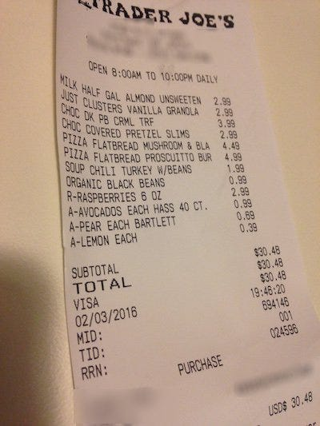

**Question audio:**

**Heard:** My two roommates and I are splitting this grocery bill evenly How much does each of us owe, and what was the most expensive thing we bought

**Tool:** `calculate({"expression": "30.48 / 3"}) -> 10.16`

**Answer:** Each of you owes ten dollars and sixteen cents. The most expensive item on the receipt was the pizza flatbread with prosciutto at four dollars and ninety nine cents.

ASR 3.52s | VLM 1.95s | TTS 2.02s | response 7.49s | $0.01155


In [8]:
q = synthesize_speech("My two roommates and I are splitting this grocery bill evenly. How much does each of us owe, and what was the most expensive thing we bought?")
_ = await point_and_ask("receipt", q)

### 2. Check a snack against a diet

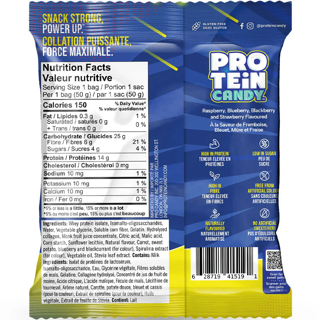

**Question audio:**

**Heard:** I'm lactose intolerant, and I'm trying to keep sugar under ten grams. Is this snack okay for me

**Answer:** No, this snack isn't okay for you because it contains milk and whey protein, so it has lactose. The sugar is fine at four grams, but the dairy makes it unsuitable.

ASR 3.55s | VLM 1.31s | TTS 2.43s | response 7.3s | $0.01115


In [9]:
q = synthesize_speech("I'm lactose intolerant and I'm trying to keep sugar under ten grams. Is this snack okay for me?")
_ = await point_and_ask("snack", q)

### 3. Pick a dish

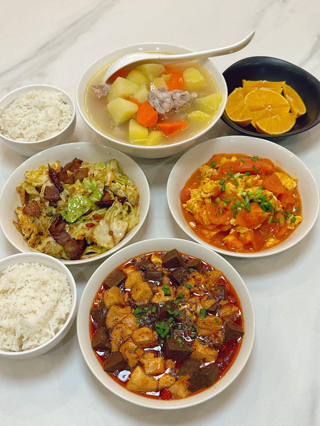

**Question audio:**

**Heard:** I can't handle spicy fo od. Which of these dishes should I go for, and which one should I skip

**Answer:** I'd go for the potato soup, tomato and egg, or plain rice since they look mild. You should probably skip the stir-fried cabbage with red chilies and the braised tofu in red sauce, as those look spicy.

ASR 3.53s | VLM 1.34s | TTS 2.49s | response 7.37s | $0.01358


In [10]:
q = synthesize_speech("I can't handle spicy food. Which of these dishes should I go for, and which one should I skip?")
_ = await point_and_ask("dinner", q)

### 4. Plan for the party

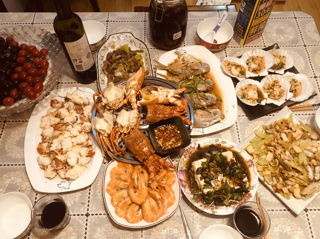

**Question audio:**

**Heard:** I'm hosting this din ner. There's no dessert on the table yet Add what I need for a simple fruit platter to my shopping list

**Tool:** `add_to_shopping_list({"items": ["strawberries", "pineapple", "cantaloupe", "honeydew melon", "kiwi"]}) -> Added 5 item(s). The list now has: strawberries, pineapple, cantaloupe, honeydew melon, kiwi`

**Answer:** I've added strawberries, pineapple, cantaloupe, honeydew melon, and kiwi to your shopping list for a simple fruit platter.

ASR 3.52s | VLM 1.4s | TTS 1.33s | response 6.25s | $0.00876

Shopping list: ['strawberries', 'pineapple', 'cantaloupe', 'honeydew melon', 'kiwi']


In [11]:
q = synthesize_speech("I'm hosting this dinner. There's no dessert on the table yet. Add what I need for a simple fruit platter to my shopping list.")
_ = await point_and_ask("party", q)
print("\nShopping list:", shopping_list)

## Latency and cost

In [12]:
report = pd.DataFrame(interactions)[["photo", "tool_calls", "question_audio_s", "asr_s", "vlm_s", "tts_s", "response_s", "cost_usd"]]
display(report.round({"cost_usd": 5}))

average = report.mean(numeric_only=True)
print(
    f"Average response time {average.response_s:.1f}s "
    f"(ASR {average.asr_s:.1f}s + vision model {average.vlm_s:.1f}s + TTS {average.tts_s:.1f}s), "
    f"average cost ${average.cost_usd:.4f} per question"
)

,photo,tool_calls,question_audio_s,asr_s,vlm_s,tts_s,response_s,cost_usd
0,receipt,1,7.0,3.52,1.95,2.02,7.49,0.01155
1,snack,0,5.3,3.55,1.31,2.43,7.30,0.01115
2,dinner,0,4.7,3.53,1.34,2.49,7.37,0.01358
3,party,1,6.4,3.52,1.40,1.33,6.25,0.00876


Average response time 7.1s (ASR 3.5s + vision model 1.5s + TTS 2.1s), average cost $0.0113 per question


## Use your own recording

To ask with your own voice, record a short WAV file on your phone or laptop (or upload one to Colab) and pass it through `load_wav`, which converts a 16-bit PCM WAV file (the format most recorders save) at any sample rate to the 16 kHz mono PCM the ASR model expects. Here we test it on a 44.1 kHz WAV file, a common recorder default.

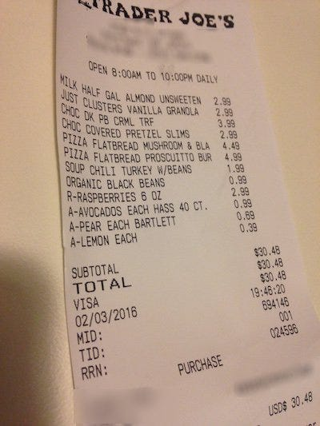

**Question audio:**

**Heard:** How many items are on this receipt

**Answer:** There are 12 items on this receipt.

ASR 3.3s | VLM 2.23s | TTS 0.59s | response 6.12s | $0.00291


In [13]:
def load_wav(path: str) -> bytes:
    """Read a 16-bit PCM WAV file and convert it to 16 kHz mono 16-bit PCM."""
    with wave.open(path, "rb") as wav:
        channels, width, rate = wav.getnchannels(), wav.getsampwidth(), wav.getframerate()
        frames = wav.readframes(wav.getnframes())
    if width != 2:
        raise ValueError("Expected a 16-bit PCM WAV file")
    samples = np.frombuffer(frames, dtype=np.int16).astype(np.float32)
    if channels > 1:
        samples = samples.reshape(-1, channels).mean(axis=1)
    if rate != SAMPLE_RATE:
        duration = len(samples) / rate
        target = np.linspace(0, duration, int(duration * SAMPLE_RATE), endpoint=False)
        samples = np.interp(target, np.arange(len(samples)) / rate, samples)
    return np.clip(samples, -32768, 32767).astype(np.int16).tobytes()


# Simulate a recording: a 44.1 kHz WAV file, as a phone or laptop would save it
recording = client.audio.speech.create(
    model=TTS_MODEL,
    input="How many items are on this receipt?",
    voice=USER_VOICE,
    response_format="wav",
    response_encoding="pcm_s16le",
    sample_rate=44_100,
)
recording_path = os.path.join(tempfile.mkdtemp(), "my_question.wav")
with open(recording_path, "wb") as f:
    f.write(recording.read())

_ = await point_and_ask("receipt", load_wav(recording_path))

To use your own file in Colab, upload it with the file browser on the left and call `await point_and_ask("receipt", load_wav("your_file.wav"))` with its name. If your recorder saves MP3 or M4A, convert it first, for example with `ffmpeg -i question.m4a -ar 16000 -ac 1 question.wav`.

## What we found

In our run, a spoken answer was ready about seven seconds after the speaker stopped. Transcription took about three and a half seconds of that, the vision model one to two seconds, and speech synthesis about two. All three models run on serverless APIs.

Each question cost about a cent, almost all of it for speech synthesis, which is priced per character. The vision model's share, including the photo and its reasoning, was well under a tenth of a cent.

Keep reasoning on when the model has tools. With reasoning off, the assistant skipped tool calls and stated wrong facts. With it on, the assistant used the calculator for the bill and called the shopping-list tool before saying it had added anything.

The transcripts had small errors ("fo od", "din ner"), and the vision model answered correctly anyway.

### Next steps

- Cartesia supports [streaming and WebSocket TTS](https://docs.together.ai/docs/inference/text-to-speech/streaming), so playback can start before the whole answer is synthesized.
- Feed live microphone audio into the same `transcription()` session instead of a synthesized clip.
- Add tools for your own use case, such as a product lookup for the snack label or an expense API for the receipt.